# Predictive Analytics: Diagnosing Tumours as Malignant or Benign
**Name:** Akshansh Srivastava | **Program:** MBA (Finance & IBM), United University, Prayagraj

**Objective:** Build and compare classification models that predict whether a tumour is malignant or benign from 30 measurements of cell nuclei, and identify the most important predictors. The same workflow (clean, split, train, compare, interpret) applies to credit-risk or loan-default models.

**Data:** Wisconsin Breast Cancer Diagnostic dataset (569 real cases, bundled with scikit-learn, so no download is needed).

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)
sns.set_theme(style='whitegrid'); RS=42
os.makedirs('figs',exist_ok=True); os.makedirs('out',exist_ok=True); R={}

## 1. Load data and check quality

In [2]:
d = load_breast_cancer(as_frame=True)
X, y = d.data.copy(), d.target.copy()          # in sklearn: 1 = benign, 0 = malignant
y = 1 - y                                      # flip so that 1 = malignant (the event we want to catch)
R['n_rows'], R['n_features'] = X.shape; R['missing']=int(X.isna().sum().sum()); R['duplicates']=int(X.duplicated().sum())
R['malignant']=int(y.sum()); R['benign']=int((y==0).sum()); R['malignant_pct']=round(y.mean()*100,1)
print(R); X.iloc[:,:6].head()

{'n_rows': 569, 'n_features': 30, 'missing': 0, 'duplicates': 0, 'malignant': 212, 'benign': 357, 'malignant_pct': np.float64(37.3)}


   mean radius  mean texture  ...  mean smoothness  mean compactness
0        17.99         10.38  ...          0.11840           0.27760
1        20.57         17.77  ...          0.08474           0.07864
2        19.69         21.25  ...          0.10960           0.15990
3        11.42         20.38  ...          0.14250           0.28390
4        20.29         14.34  ...          0.10030           0.13280

[5 rows x 6 columns]

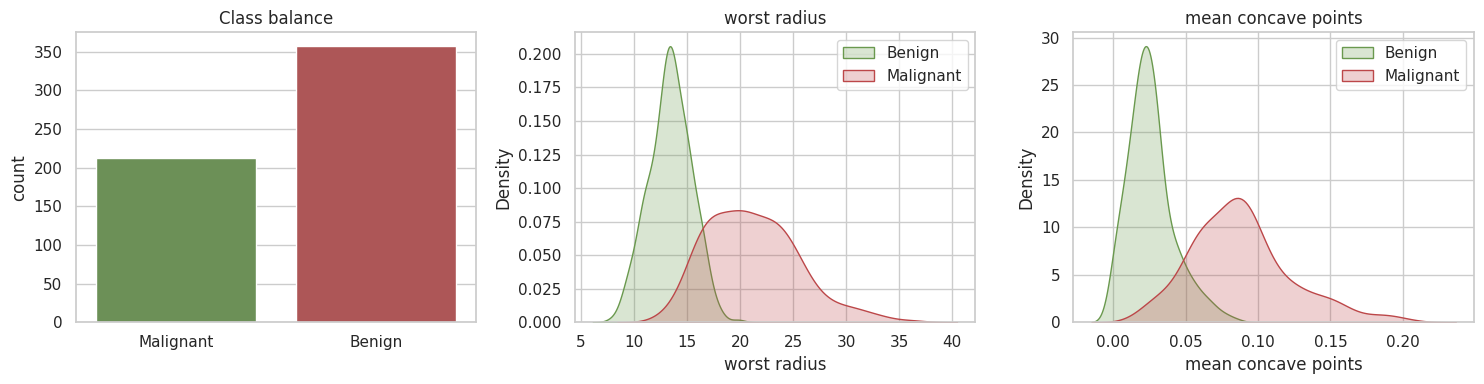

In [3]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
sns.countplot(x=y.map({0:'Benign',1:'Malignant'}), hue=y.map({0:'Benign',1:'Malignant'}), ax=ax[0], palette=['#6a994e','#bc4749'], legend=False); ax[0].set_title('Class balance'); ax[0].set_xlabel('')
for a,f in zip(ax[1:],['worst radius','mean concave points']):
    sns.kdeplot(x=X[f][y==0], ax=a, fill=True, label='Benign', color='#6a994e'); sns.kdeplot(x=X[f][y==1], ax=a, fill=True, label='Malignant', color='#bc4749'); a.set_title(f); a.legend()
plt.tight_layout(); plt.savefig('figs/eda.png',dpi=130,bbox_inches='tight'); plt.show()

worst concave points    0.793566
worst perimeter         0.782914
mean concave points     0.776614
worst radius            0.776454
mean perimeter          0.742636
dtype: float64

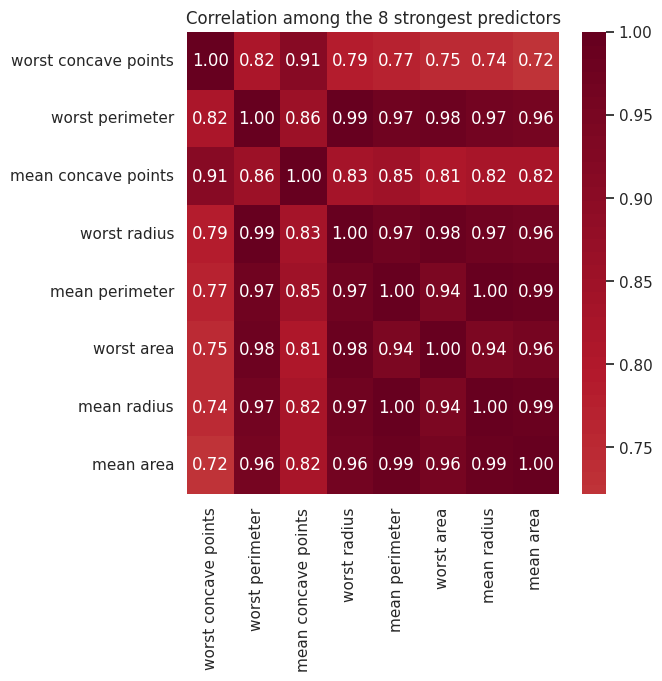

In [4]:
corr_y = X.corrwith(y).sort_values(key=abs, ascending=False)
R['top_corr']=[[k,round(v,2)] for k,v in corr_y.head(5).items()]
plt.figure(figsize=(6,6)); sns.heatmap(X[list(corr_y.index[:8])].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation among the 8 strongest predictors'); plt.savefig('figs/corr.png',dpi=130,bbox_inches='tight'); plt.show(); corr_y.head(5)

## 2. Train/test split (80/20, stratified) and models

In [5]:
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.2,stratify=y,random_state=RS)
R['train'],R['test']=len(Xtr),len(Xte)
models = {
 'Logistic Regression': Pipeline([('sc',StandardScaler()),('m',LogisticRegression(max_iter=2000))]),
 'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RS),
 'Gradient Boosting': GradientBoostingClassifier(random_state=RS)}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
rows=[]; probs={}; preds={}
for n,m in models.items():
    m.fit(Xtr,ytr); p=m.predict(Xte); pr=m.predict_proba(Xte)[:,1]; probs[n]=pr; preds[n]=p
    rows.append([n, accuracy_score(yte,p), precision_score(yte,p), recall_score(yte,p), f1_score(yte,p), roc_auc_score(yte,pr),
                 cross_val_score(m,X,y,cv=cv,scoring='accuracy').mean()])
res = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1','ROC-AUC','5-fold CV Acc']).set_index('Model')
res.round(3).to_csv('out/results.csv'); R['results']=res.round(3).to_dict('index'); res.round(3)

                     Accuracy  Precision  Recall     F1  ROC-AUC  5-fold CV Acc
Model                                                                          
Logistic Regression     0.965      0.975   0.929  0.951    0.996          0.974
Random Forest           0.974      1.000   0.929  0.963    0.994          0.953
Gradient Boosting       0.965      1.000   0.905  0.950    0.995          0.951

## 3. Tune the best tree model

In [6]:
gs = GridSearchCV(RandomForestClassifier(random_state=RS), {'n_estimators':[200,400],'max_depth':[None,5,10],'min_samples_leaf':[1,3]}, cv=cv, scoring='recall', n_jobs=-1).fit(Xtr,ytr)
best = gs.best_estimator_; R['best_params']=gs.best_params_
pt = best.predict(Xte); prt = best.predict_proba(Xte)[:,1]; probs['Tuned Random Forest']=prt; preds['Tuned Random Forest']=pt
R['tuned']={k:round(float(f(yte,pt)),3) for k,f in [('Accuracy',accuracy_score),('Precision',precision_score),('Recall',recall_score),('F1',f1_score)]}; R['tuned']['ROC-AUC']=round(float(roc_auc_score(yte,prt)),3)
print(gs.best_params_, R['tuned'])

{'max_depth': 5, 'min_samples_leaf': 3, 'n_estimators': 400} {'Accuracy': 0.974, 'Precision': 1.0, 'Recall': 0.929, 'F1': 0.963, 'ROC-AUC': 0.995}


## 4. Confusion matrices and ROC curves

{'Logistic Regression': [[71, 1], [3, 39]], 'Random Forest': [[72, 0], [3, 39]], 'Gradient Boosting': [[72, 0], [4, 38]], 'Tuned Random Forest': [[72, 0], [3, 39]]}

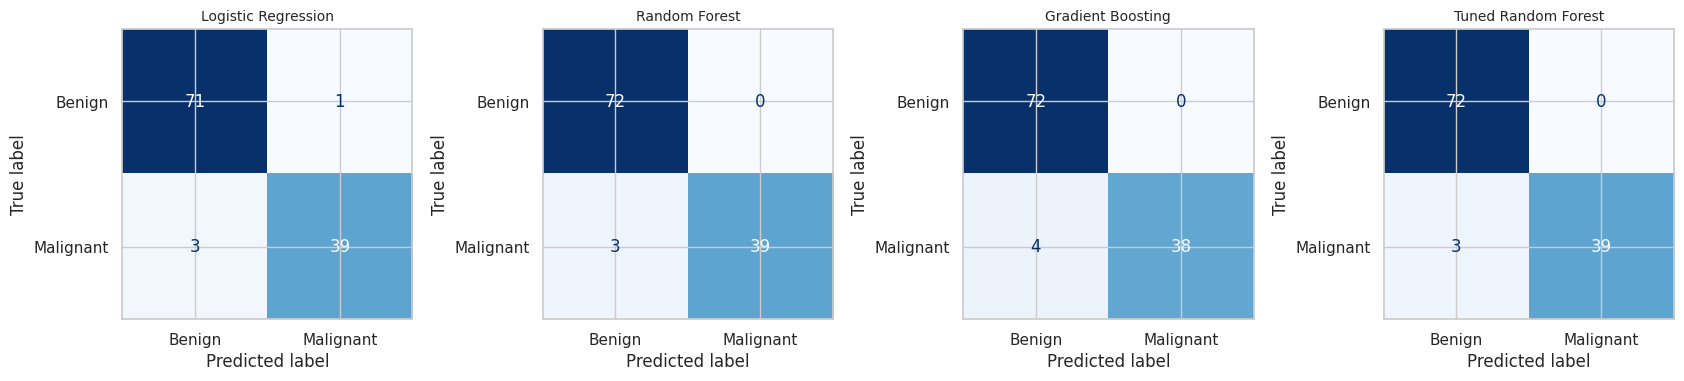

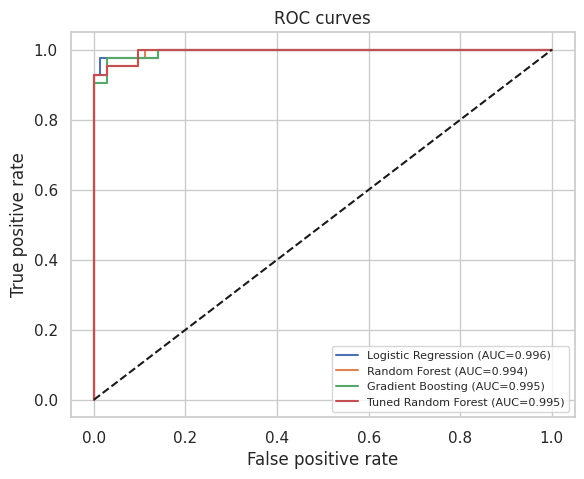

In [7]:
names=['Logistic Regression','Random Forest','Gradient Boosting','Tuned Random Forest']
fig,ax=plt.subplots(1,4,figsize=(17,4))
for a,n in zip(ax,names):
    ConfusionMatrixDisplay(confusion_matrix(yte,preds[n]), display_labels=['Benign','Malignant']).plot(ax=a,colorbar=False,cmap='Blues'); a.set_title(n,fontsize=10)
plt.tight_layout(); plt.savefig('figs/cm.png',dpi=130,bbox_inches='tight'); plt.show()
R['cm']={n:confusion_matrix(yte,preds[n]).tolist() for n in names}
plt.figure(figsize=(6.5,5))
for n in names:
    f,t,_=roc_curve(yte,probs[n]); plt.plot(f,t,label=f'{n} (AUC={roc_auc_score(yte,probs[n]):.3f})')
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves'); plt.legend(fontsize=8)
plt.savefig('figs/roc.png',dpi=130,bbox_inches='tight'); plt.show(); R['cm']

## 5. Which features matter most?

worst area              0.153134
worst perimeter         0.138232
worst concave points    0.114402
worst radius            0.094830
mean concave points     0.090790
dtype: float64

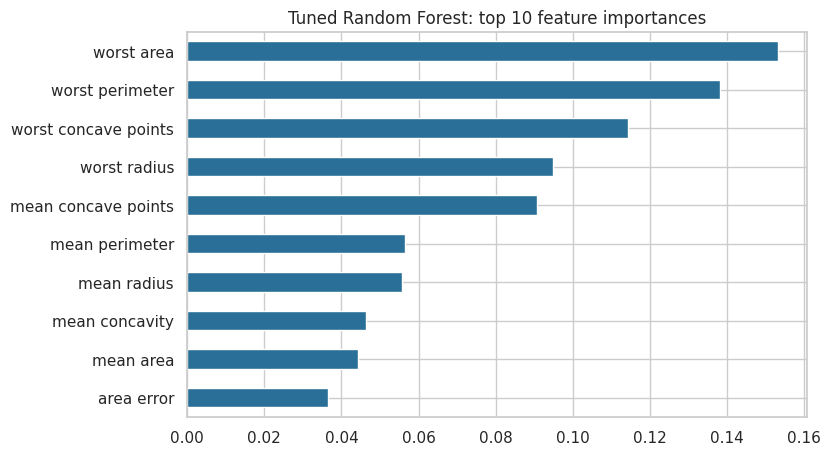

In [8]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind='barh', figsize=(8,5), color='#2a6f97'); plt.title('Tuned Random Forest: top 10 feature importances')
plt.savefig('figs/imp.png',dpi=130,bbox_inches='tight'); plt.show()
R['top_imp']=[[k,round(v,3)] for k,v in imp.tail(5)[::-1].items()]; imp.tail(5)[::-1]

## 7. Decision threshold: trading false negatives for false positives

   Threshold  Accuracy  Precision  Recall  False positives  False negatives
0        0.5     0.974      1.000   0.929                0                3
1        0.4     0.965      0.975   0.929                1                3
2        0.3     0.965      0.975   0.929                1                3
3        0.2     0.921      0.851   0.952                7                2
4        0.1     0.886      0.764   1.000               13                0

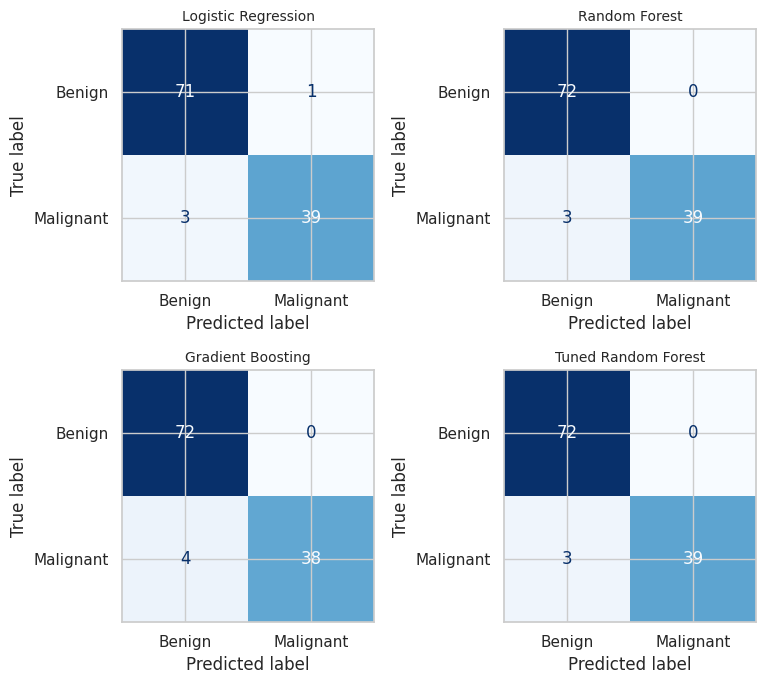

In [9]:
rows=[]
for t in [0.5,0.4,0.3,0.2,0.1]:
    p=(prt>=t).astype(int); a,b,c_,d_=confusion_matrix(yte,p).ravel()
    rows.append([t, accuracy_score(yte,p), precision_score(yte,p), recall_score(yte,p), int(b), int(c_)])
thr=pd.DataFrame(rows,columns=['Threshold','Accuracy','Precision','Recall','False positives','False negatives']).round(3)
thr.to_csv('out/threshold.csv',index=False); R['threshold']=thr.values.tolist()
fig,ax=plt.subplots(2,2,figsize=(8,7))
for a,n in zip(ax.ravel(),names):
    ConfusionMatrixDisplay(confusion_matrix(yte,preds[n]), display_labels=['Benign','Malignant']).plot(ax=a,colorbar=False,cmap='Blues'); a.set_title(n,fontsize=10)
plt.tight_layout(); plt.savefig('figs/cm2.png',dpi=130,bbox_inches='tight'); plt.show(); thr

## 8. Error analysis

In [10]:
tn,fp,fn,tp = confusion_matrix(yte,pt).ravel(); R['errors']={'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
print(R['errors'])
json.dump(R, open('out/results.json','w'), indent=1, default=str)

{'TN': 72, 'FP': 0, 'FN': 3, 'TP': 39}
